#### K-Means
K-Means is an unsupervised machine learning algorithm used for clustering.

Unlike classification, clustering does not require predefined class labels.

It groups similar data points together based on their features.

In [1]:
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [2]:
# Load dataset
iris = load_iris()
X = iris.data

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [3]:
# Create K-Means model
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Train model and predict clusters
clusters = kmeans.fit_predict(X_scaled)

print("Cluster assignments:")
print(clusters)

print("Centroids:")
print(kmeans.cluster_centers_)

C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\PMLS\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs

Cluster assignments:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]
Centroids:
[[-0.05021989 -0.88337647  0.34773781  0.2815273 ]
 [-1.01457897  0.85326268 -1.30498732 -1.25489349]
 [ 1.13597027  0.08842168  0.99615451  1.01752612]]


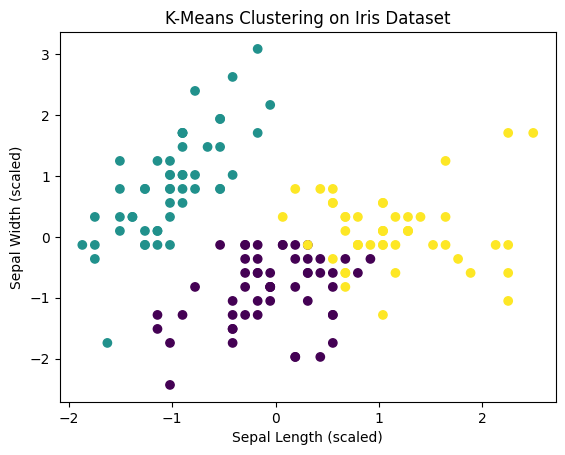

In [ ]:
plt.scatter(X_scaled[:, 0],X_scaled[:, 1],c = clusters, cmap="viridis")

plt.xlabel("Sepal Length (scaled)")
plt.ylabel("Sepal Width (scaled)")
plt.title("K-Means Clustering on Iris Dataset")

plt.show()

#### Elbow Method


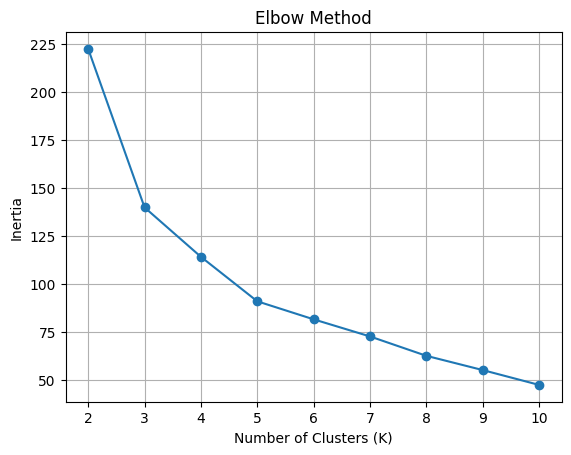

In [4]:


# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Store inertia values
inertia_values = []

# different values of K
for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia_values.append(kmeans.inertia_)

# Elbow Curve plot
plt.plot(range(2, 11), inertia_values, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

#### Silhouette Score
The Silhouette Score measures how well each data point fits within its assigned cluster compared with other clusters.

It considers two things:
1. Cohesion: How close a data point is to other points in its own cluster.
2. Separation: How far a data point is from points in other clusters.

K = 2, Silhouette Score = 0.5818
K = 3, Silhouette Score = 0.4599
K = 4, Silhouette Score = 0.3869
K = 5, Silhouette Score = 0.3459
K = 6, Silhouette Score = 0.3171
K = 7, Silhouette Score = 0.3202
K = 8, Silhouette Score = 0.3387
K = 9, Silhouette Score = 0.3424
K = 10, Silhouette Score = 0.3518


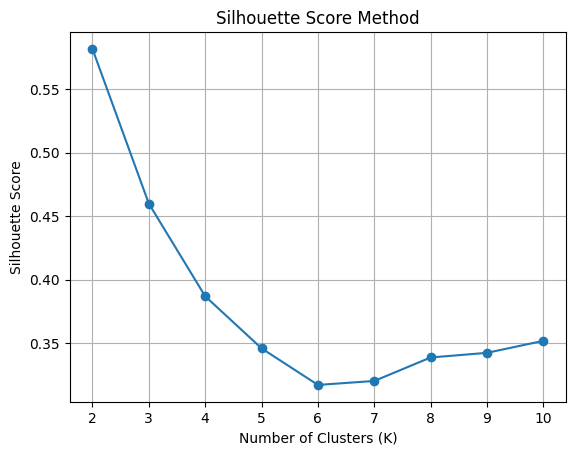

In [5]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Load dataset
iris = load_iris()
X = iris.data

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

silhouette_values = []

# Test different K values
for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    clusters = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, clusters)

    silhouette_values.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

# Plot scores
plt.plot(range(2, 11), silhouette_values, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Method")

plt.xticks(range(2, 11))
plt.grid(True)
plt.show()